[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bethavila17/dncp-riesgo-contrataciones/blob/main/notebooks/02_exploracion_e_indicadores.ipynb)

# 2. Exploración, indicadores de riesgo y su validación
**Proyecto III Big Data — Maestría en Ciencia de Datos (UCOM)** · Bethania Avila, Arturo Fernández, Gustavo Bogado

Se describen los procesos, se construyen las banderas rojas por etapa (planificación, convocatoria, adjudicación y contrato) y se **validan** antes de sumarlas en un índice: siguiendo a Fazekas y Kocsis (2020), una bandera entra al índice compuesto (CRI) solo si se asocia significativamente con el oferente único.

In [1]:
# Configuración del entorno (Google Colab o local)
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/bethavila17/dncp-riesgo-contrataciones.git"  # <- URL del repositorio en GitHub
USAR_DRIVE = False  # True: guarda el data lake en Google Drive y no repite descargas entre sesiones

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    RAIZ = Path("/content/dncp-riesgo-contrataciones")
    if not RAIZ.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(RAIZ)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(RAIZ / "requirements-colab.txt")], check=True)
    if USAR_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        os.environ["DNCP_DATA_DIR"] = "/content/drive/MyDrive/dncp_data_lake"
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "src"))

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dncp_riesgo import graficos as gr
from dncp_riesgo.pipeline import asegurar_datos, preparar

cfg, lake = preparar()
gr.estilo()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
print("Entorno:", "Google Colab" if EN_COLAB else "local", "| años:", cfg["fuentes"]["ocp_registry"]["anios"])

Entorno: local | años: [2020, 2021, 2022, 2023, 2024, 2025, 2026]


In [2]:
asegurar_datos(lake, cfg, hasta="gold")
ind = lake.leer_gold("indicadores")
series = lake.leer_gold("series_mensuales").sort_values("mes")
print(f"{len(ind):,} procesos con convocatoria desde 2020 | adjudicados: {int(ind.adjudicado.sum()):,}".replace(",", "."))

00:03:27 | dncp | Datos listos hasta la etapa 'gold' (no se repite el procesamiento).


58.621 procesos con convocatoria desde 2020 | adjudicados: 50.152


## 2.1 Estacionalidad: pico de convocatorias en septiembre–octubre y caída a fin de año

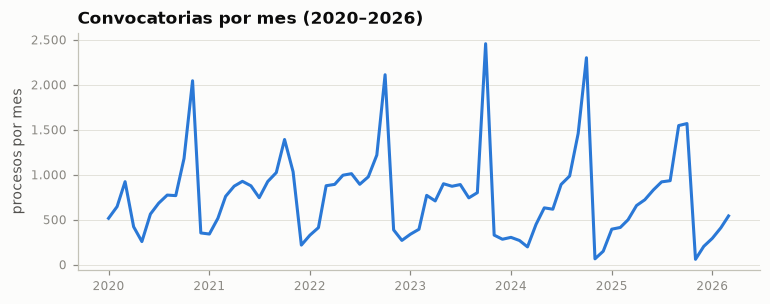

In [3]:
s = series[series["mes"] < cfg["series"]["fecha_fin"]]
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(s["mes"], s["n_procesos"], color=gr.SERIES[0])
ax.set_ylabel("procesos por mes"); ax.yaxis.set_major_formatter(gr.formato_es(0))
ax.set_title("Convocatorias por mes (2020–2026)")
gr.guardar(fig, "fig02_estacionalidad"); plt.show()

## 2.2 Oferente único por año (IC de Wilson al 95 %)
La Ley 7021/2022 entró en vigencia en febrero de 2024 y cambió las modalidades.

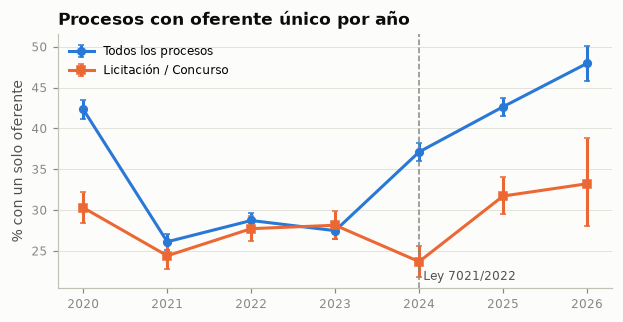

In [4]:
base = ind[ind["oferente_unico"].notna()]
fig, ax = plt.subplots(figsize=(6.5, 3))
for (nombre, sub), color, mk in zip([("Todos los procesos", base), ("Licitación / Concurso", base[base.metodo_grupo == "Licitación / Concurso"])],
                                    gr.SERIES, ["o", "s"]):
    g = sub.groupby("anio")["oferente_unico"].agg(["sum", "count"])
    p, lo, hi = gr.wilson(g["sum"], g["count"])
    ax.errorbar(g.index, p, yerr=[p - lo, hi - p], fmt=mk + "-", color=color, ms=5, lw=2, capsize=2, label=nombre)
ax.axvline(2024, ls="--", color=gr.TENUE, lw=1); ax.text(2024.05, ax.get_ylim()[0] + 1, "Ley 7021/2022", fontsize=8, color=gr.TINTA_2)
ax.set_ylabel("% con un solo oferente"); ax.yaxis.set_major_formatter(gr.formato_es(0)); ax.legend()
ax.set_title("Procesos con oferente único por año")
gr.guardar(fig, "fig03_oferente_unico"); plt.show()

## 2.3 Concentración del mercado de proveedores (curva de Lorenz)

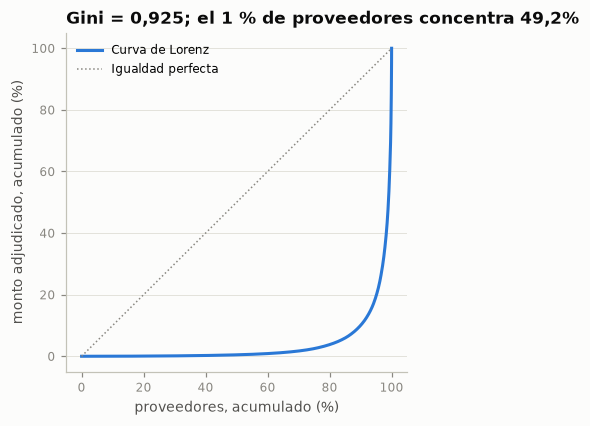

6.021 proveedores adjudicados


In [5]:
m = ind.dropna(subset=["monto_adjudicado", "proveedor_id"]).groupby("proveedor_id")["monto_adjudicado"].sum().sort_values().to_numpy()
lorenz = np.insert(np.cumsum(m) / m.sum(), 0, 0)
gini = 1 - 2 * np.trapezoid(lorenz, dx=1 / len(m))
top1 = m[-max(1, len(m) // 100):].sum() / m.sum()
fig, ax = plt.subplots(figsize=(4, 4))
xs = np.linspace(0, 100, len(lorenz))
ax.plot(xs, lorenz * 100, color=gr.SERIES[0], label="Curva de Lorenz"); ax.plot([0, 100], [0, 100], ls=":", color=gr.TENUE, lw=1, label="Igualdad perfecta")
ax.set_xlabel("proveedores, acumulado (%)"); ax.set_ylabel("monto adjudicado, acumulado (%)"); ax.legend(loc="upper left")
ax.set_title(f"Gini = {gini:.3f}; el 1 % de proveedores concentra {top1:.1%}".replace(".", ","))
gr.guardar(fig, "fig04_lorenz"); plt.show()
print(f"{len(m):,} proveedores adjudicados".replace(",", "."))

## 2.4 Por qué las protestas no son una etiqueta de irregularidad
La proporción de procesos con protesta crece con la cantidad de oferentes: más oferentes, más perdedores que pueden protestar.

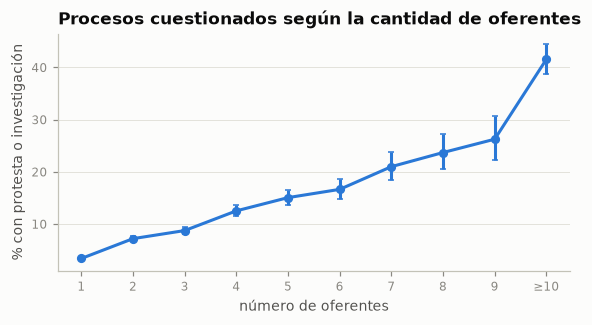

In [6]:
adj = ind[(ind.adjudicado == 1) & ind.n_oferentes.notna()]
g = adj.groupby(adj["n_oferentes"].clip(upper=10))["y_queja"].agg(["sum", "count"])
p, lo, hi = gr.wilson(g["sum"], g["count"])
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.errorbar(g.index, p, yerr=[p - lo, hi - p], fmt="o-", color=gr.SERIES[0], capsize=2)
ax.set_xticks(range(1, 11), [str(i) for i in range(1, 10)] + ["≥10"])
ax.set_xlabel("número de oferentes"); ax.set_ylabel("% con protesta o investigación"); ax.yaxis.set_major_formatter(gr.formato_es(0))
ax.set_title("Procesos cuestionados según la cantidad de oferentes")
gr.guardar(fig, "fig05_protestas_oferentes"); plt.show()

## 2.5 Calidad de datos (veracidad)

In [7]:
pd.Series({
    "Adjudicaciones en guaraníes declaradas como USD (moneda corregida)": int(ind.moneda_corregida.sum()),
    "Monto adjudicado inconsistente (> 10 veces el estimado o > 5 billones)": int(ind.alerta_monto.sum()),
    "Plazo de convocatoria fuera de [0, 365] días": int(ind.alerta_plazo.sum()),
    "Fecha de adjudicación fuera de [0, 730] días del cierre": int(ind.alerta_evaluacion.sum()),
}, name="procesos").to_frame()

,procesos
Adjudicaciones en guaraníes declaradas como USD (moneda corregida),33
Monto adjudicado inconsistente (> 10 veces el estimado o > 5 billones),136
"Plazo de convocatoria fuera de [0, 365] días",23
"Fecha de adjudicación fuera de [0, 730] días del cierre",117


## 2.6 Banderas rojas candidatas por etapa

In [8]:
from dncp_riesgo.procesamiento import BANDERAS, ETAPA_BANDERA
adj = ind[ind.adjudicado == 1]
from dncp_riesgo.procesamiento import NOMBRES_BANDERAS
pd.DataFrame({"etapa": ETAPA_BANDERA, "bandera": NOMBRES_BANDERAS, "regla": BANDERAS,
              "evaluables": adj[list(BANDERAS)].notna().sum(), "prevalencia_%": (adj[list(BANDERAS)].mean() * 100).round(1)})

,etapa,bandera,regla,evaluables,prevalencia_%
bandera_plazo_corto,Convocatoria,Plazo corto,Plazo de convocatoria menor al percentil 10 de su modalidad,47967,4.9
bandera_oferente_unico,Adjudicación,Oferente único,Un solo oferente en un procedimiento competitivo,46949,32.5
bandera_excepcion,Convocatoria,Excepción,Contratación por vía de la excepción,50152,6.2
bandera_sobrecosto,Adjudicación,Adjudicado > estimado,Monto adjudicado supera al estimado,49628,8.7
bandera_sobreprecio_items,Adjudicación,Sobreprecio por ítem,"Precio unitario adjudicado > 1,5 veces la mediana de mercado del ítem",30932,21.2
bandera_evaluacion_larga,Adjudicación,Evaluación prolongada,Evaluación de ofertas mayor al percentil 90 de su modalidad,47928,9.6
bandera_proveedor_dominante,Adjudicación,Proveedor dominante,El proveedor concentra >= 25 % de lo adjudicado por la entidad en los 12 meses previos,48920,3.7
bandera_proveedor_nuevo,Adjudicación,Proveedor nuevo,Proveedor sin historial gana un monto alto (percentil 90 de su categoría),50152,0.9
bandera_fin_de_anio,Planificación,Fin de año,Convocatoria publicada en noviembre o diciembre,50152,9.0
bandera_ampliacion,Contrato,Ampliación de monto,Ampliaciones del contrato > 20 % del monto,47678,1.3


## 2.7 Validación de constructo (regresión logística del oferente único, periodo de entrenamiento)

In [9]:
from dncp_riesgo.modelos import preparar_conjunto, validar_banderas, indice_cri
cj = preparar_conjunto(ind, cfg)
tabla_or, cri_banderas, resumen = validar_banderas(cj.datos.loc[cj.entrenamiento])
print(f"n = {resumen['n']:,} | pseudo-R² de McFadden = {resumen['pseudo_r2_mcfadden']:.3f}".replace(",", "."))
print("Banderas del CRI:", cri_banderas)
tabla_or

n = 30.779 | pseudo-R² de McFadden = 0.037
Banderas del CRI: ['bandera_oferente_unico', 'bandera_excepcion', 'bandera_sobrecosto', 'bandera_proveedor_dominante', 'bandera_fin_de_anio']


,bandera,nombre,descripcion,etapa,prevalencia_%,odds_ratio,ic95_inf,ic95_sup,p_valor,integra_cri
0,bandera_plazo_corto,Plazo corto,Plazo de convocatoria menor al percentil 10 de su modalidad,Convocatoria,5.8,1.103,0.989,1.230,7.850226e-02,False
1,bandera_sobrecosto,Adjudicado > estimado,Monto adjudicado supera al estimado,Adjudicación,8.6,1.743,1.601,1.897,7.084944e-38,True
2,bandera_sobreprecio_items,Sobreprecio por ítem,"Precio unitario adjudicado > 1,5 veces la mediana de mercado del ítem",Adjudicación,22.2,0.847,0.784,0.915,2.442559e-05,False
3,bandera_evaluacion_larga,Evaluación prolongada,Evaluación de ofertas mayor al percentil 90 de su modalidad,Adjudicación,9.9,0.394,0.355,0.437,4.374734e-69,False
4,bandera_proveedor_dominante,Proveedor dominante,El proveedor concentra >= 25 % de lo adjudicado por la entidad en los 12 meses previos,Adjudicación,3.0,1.353,1.162,1.575,1.007507e-04,True
5,bandera_proveedor_nuevo,Proveedor nuevo,Proveedor sin historial gana un monto alto (percentil 90 de su categoría),Adjudicación,0.9,0.846,0.600,1.193,3.415709e-01,False
6,bandera_fin_de_anio,Fin de año,Convocatoria publicada en noviembre o diciembre,Planificación,7.1,1.340,1.213,1.480,8.879120e-09,True
7,bandera_ampliacion,Ampliación de monto,Ampliaciones del contrato > 20 % del monto,Contrato,1.5,0.680,0.459,1.008,5.466140e-02,False


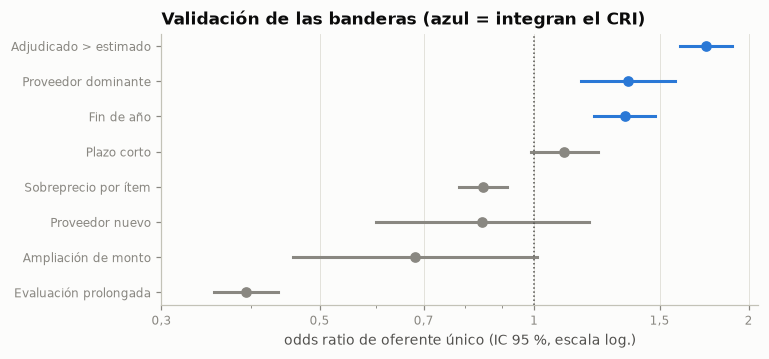

In [10]:
t = tabla_or.sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(7, 3.2))
for i, r in enumerate(t.itertuples()):
    color = gr.SERIES[0] if r.integra_cri else gr.TENUE
    ax.plot([r.ic95_inf, r.ic95_sup], [i, i], color=color, lw=2)
    ax.plot(r.odds_ratio, i, "o", color=color, ms=6)
ax.axvline(1, ls=":", color=gr.TINTA_2, lw=1); ax.set_xscale("log")
from matplotlib.ticker import NullFormatter
ax.set_xticks([0.3, 0.5, 0.7, 1, 1.5, 2], ["0,3", "0,5", "0,7", "1", "1,5", "2"]); ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_yticks(range(len(t)), t.nombre)
ax.set_xlabel("odds ratio de oferente único (IC 95 %, escala log.)"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Validación de las banderas (azul = integran el CRI)")
gr.guardar(fig, "fig06_validacion_banderas"); plt.show()

In [11]:
d = cj.datos.assign(cri=indice_cri(cj.datos, cri_banderas))
d.groupby("metodo_grupo")["cri"].agg(["mean", "count"]).round(3).sort_values("mean", ascending=False)

,mean,count
metodo_grupo,,
Excepción,0.292,2400
Menor cuantía / Directa,0.106,27456
Licitación / Concurso,0.088,12431
"Otros (organismos multilaterales, consultoría)",0.080,155
Subasta electrónica,0.037,260
